# 06 The final exam: score it, and rank the patterns

**What this notebook is.** Until now every choice was made on the validation part. This notebook opens the test
part, the wafers the model has never seen, and scores the model once. These are the final numbers.

**Why only once.** If I look at the test score, go back, change the model and score again, I'm tuning on the exam.
Then the test part is just a second practice test and the score isn't honest. So this notebook runs once, at the
end. If something has to change, it changes in notebook 05 on validation.

**What it answers.** How often the model finds each defect, how often it gets a whole wafer right, how that
changes with more defects on one wafer, and which of the 8 defects is the biggest problem. That ranking is the
main question of the project.

**In:** `output/features.npz`, `output/split.npz`, `output/forest.joblib`, `output/simple_model.joblib` **Out:** four files in `output/`

## 1. Load the model and the test part

**Why this step:** The test features were made in notebook 03 and saved without being looked at. Now is the first time.

**The problem:** Load the trained forest and the test wafers' features and answers.

**How:** `joblib.load` opens the forest notebook 05 saved. I also load the baseline from notebook 04, the simple model QC-04 compares with, and the training answers, only to rebuild the guess by share from notebook 04 on the same test wafers.

In [1]:
import csv
import os

import numpy as np
import matplotlib.pyplot as plt
import joblib

import wafer

f = np.load("output/features.npz", allow_pickle=True)
X_test = f["X_test"]
y_test = f["y_test"]
y_train = f["y_train"]

forest = joblib.load("output/forest.joblib")
simple = joblib.load("output/simple_model.joblib")
print("Test wafers:", len(y_test))
print("Trees in the forest:", len(forest.estimators_))

Test wafers: 5535
Trees in the forest: 300


**What you should see:** The number of test wafers and of trees in the forest.

## 2. Look at a few answers first

**Why this step:** A table of percentages can hide a model that answers nonsense. Ten answers next to the truth show quickly whether it makes sense.

**The problem:** Predict every test wafer, and print the first 10 next to the real label.

**How:** `forest.predict(X_test)` gives an answer for every test wafer, 8 positions each. `wafer.label_name` turns both into names so I can read them.\
I pick the 10 at random with `rng.choice` and seed 42, because the test part is sorted by type: the first 10 would all be the same type.

In [2]:
y_pred = forest.predict(X_test)

# 10 at random, because the test part is sorted by type and the first 10 are all the same type
rng = np.random.default_rng(42)
for i in rng.choice(len(y_test), 10, replace=False):
    true_name = wafer.label_name(y_test[i])
    said_name = wafer.label_name(y_pred[i])
    if true_name == said_name:
        print(f"true: {true_name}  |  model: {said_name}")
    else:
        print(f"true: {true_name}  |  model: {said_name}   <- WRONG")

true: Center + Edge-Ring  |  model: Center + Edge-Ring
true: Edge-Ring + Loc + Scratch  |  model: Edge-Ring + Loc + Scratch
true: Center + Edge-Ring  |  model: Center + Edge-Ring
true: Edge-Loc  |  model: Edge-Loc
true: Donut + Edge-Loc + Loc + Scratch  |  model: Donut + Edge-Loc + Loc + Scratch
true: Donut + Edge-Ring  |  model: Donut + Edge-Ring + Scratch   <- WRONG
true: Edge-Ring  |  model: Edge-Ring
true: Center + Edge-Ring  |  model: Center + Edge-Ring
true: Center + Edge-Ring + Loc  |  model: Center + Edge-Ring + Scratch   <- WRONG
true: Loc  |  model: Loc


**What you should see:** Ten pairs. Count how many match, and when one is wrong, whether a defect was missed or
one was added.

## 3. Recall and precision per defect, next to the baselines

**Why this step:** QC-01 asks for at least 70% recall on every defect, QC-03 for at least 60% precision, and QC-04 that the forest has a higher F1 than the simple model on every defect. All three are per defect, so one average wouldn't do.

**The problem:** Score every defect, for the forest, for the simple model and for the guess by share.

**How:** Recall: of the wafers that really have the defect, how many the model caught. Precision: of the wafers it flagged, how many really had it. F1: one number that is only high when both are (all three explained in notebook 04).\
**The baselines:** the simple model from notebook 04 predicts the test wafers, the same way the forest does. The guess by share from notebook 04 is rebuilt with the same seed: yes on a random part of the wafers as big as each defect's share in training. It's the luck floor, to show how far above luck both models are.\
`np.argmin` gives the position of the smallest number, so I can name the weakest defect.

In [3]:
# The baseline QC-04 compares with: the simple model from notebook 04
y_base = simple.predict(X_test)

# The guess by share from notebook 04, the luck floor: yes as often as each defect is on the training wafers
rng = np.random.default_rng(42)
y_luck = (rng.random(y_test.shape) < y_train.mean(axis=0)).astype(y_test.dtype)

recall, precision = wafer.scores_per_defect(y_test, y_pred)
base_recall, base_precision = wafer.scores_per_defect(y_test, y_base)
luck_recall, luck_precision = wafer.scores_per_defect(y_test, y_luck)
f1 = wafer.f1_per_defect(recall, precision)
base_f1 = wafer.f1_per_defect(base_recall, base_precision)
luck_f1 = wafer.f1_per_defect(luck_recall, luck_precision)

for i in range(len(wafer.DEFECTS)):
    print(f"{wafer.DEFECTS[i]}: recall {recall[i] * 100:.1f}%, precision {precision[i] * 100:.1f}%, F1 {f1[i] * 100:.1f}%"
          f" | F1 simple model {base_f1[i] * 100:.1f}%, guess by share {luck_f1[i] * 100:.1f}%")

worst = np.argmin(recall)
worst_p = np.argmin(precision)
print()
print(f"Lowest recall: {wafer.DEFECTS[worst]} {recall[worst] * 100:.1f}% (QC-01: at least 70%)")
print(f"Lowest precision: {wafer.DEFECTS[worst_p]} {precision[worst_p] * 100:.1f}% (QC-03: at least 60%)")
print("Higher F1 than the simple model on every defect:", (f1 > base_f1).all())

Center: recall 94.5%, precision 93.5%, F1 94.0% | F1 simple model 86.5%, guess by share 32.6%
Donut: recall 93.8%, precision 96.3%, F1 95.1% | F1 simple model 87.9%, guess by share 32.0%
Edge-Loc: recall 84.4%, precision 92.8%, F1 88.4% | F1 simple model 0.0%, guess by share 31.8%
Edge-Ring: recall 95.3%, precision 91.7%, F1 93.5% | F1 simple model 92.0%, guess by share 32.0%
Loc: recall 87.5%, precision 95.4%, F1 91.3% | F1 simple model 83.1%, guess by share 48.0%
Near-Full: recall 100.0%, precision 87.5%, F1 93.3% | F1 simple model 95.2%, guess by share 0.0%
Scratch: recall 86.0%, precision 76.9%, F1 81.2% | F1 simple model 60.0%, guess by share 48.7%
Random: recall 71.1%, precision 97.6%, F1 82.2% | F1 simple model 17.6%, guess by share 1.7%

Lowest recall: Random 71.1% (QC-01: at least 70%)
Lowest precision: Scratch 76.9% (QC-03: at least 60%)
Higher F1 than the simple model on every defect: False


**What you should see:** Recall, precision and F1 per defect, next to the F1 of the simple model and of the guess by share.
Then the lowest recall and the lowest precision next to their QC minimums, and whether the forest has a higher F1
than the simple model on every defect. Notebook 08
gives the Pass or Fail.

## 4. All 8 right (QC-02)

**Why this step:** This is the strictest score and the one published models report, so it's the one I compare with them.

**The problem:** The share of test wafers where all 8 positions are correct.

**How:** One missed or one extra defect and the whole wafer counts as wrong.

In [4]:
all_right = wafer.share_all_eight_right(y_test, y_pred)
base_all_right = wafer.share_all_eight_right(y_test, y_base)

print(f"All 8 right, my model: {all_right * 100:.1f}% (QC-02: at least 60%, aim 80%)")
print(f"All 8 right, simple model: {base_all_right * 100:.1f}%")
print(f"All 8 right, guess by share: {wafer.share_all_eight_right(y_test, y_luck) * 100:.1f}%")

All 8 right, my model: 68.3% (QC-02: at least 60%, aim 80%)
All 8 right, simple model: 31.2%
All 8 right, guess by share: 1.9%


**What you should see:** All 8 right for the forest, the simple model and the guess by share, next to QC-02's minimum of 60% and aim of
80%.

## 5. Harder with more defects? (FR-07)

**Why this step:** Published models get worse when a wafer has three or four defects. So this is where to compare with them.

**The problem:** Score all 8 right separately for wafers with 0, 1, 2, 3 and 4 defects.

**How:** `y_test.sum(axis=1)` adds up the 8 positions of every wafer, so it's the number of defects on it, 0 for Normal. Then I pick the wafers with that number and score only those.\
DC-Net, the model from the dataset's authors, gets 89.74% on three defects, 89.61% on four and 93.20% overall (Shukla, 2023). Their score is accuracy over the 38 types, and getting the type right is the same as all 8 right, so the numbers can stand side by side. Two limits: Shukla's paper is a preprint that was withdrawn on 17 October 2023, and it split the data randomly 80/20 with the copies still in, so a copy could sit on both sides. So DC-Net's numbers are a reference point, not a like-for-like comparison.

In [5]:
how_many = y_test.sum(axis=1)     # number of defects per wafer, 0 = Normal

per_number = []
for n in range(0, 5):
    here = how_many == n
    if here.sum() == 0:
        continue
    score = wafer.share_all_eight_right(y_test[here], y_pred[here])
    per_number.append([n, here.sum(), score])
    print(f"{n} defects: {here.sum():,} wafers, all 8 right {score * 100:.1f}%")

print(f"All wafers: {all_right * 100:.1f}%")
print("DC-Net: 3 defects 89.74%, 4 defects 89.61%, overall 93.20%")

0 defects: 150 wafers, all 8 right 100.0%
1 defects: 1,035 wafers, all 8 right 88.1%
2 defects: 1,950 wafers, all 8 right 68.4%
3 defects: 1,800 wafers, all 8 right 53.4%
4 defects: 600 wafers, all 8 right 70.7%
All wafers: 68.3%
DC-Net: 3 defects 89.74%, 4 defects 89.61%, overall 93.20%


**What you should see:** All 8 right per number of defects on a wafer, next to DC-Net. Where does the score drop
most, and does it keep dropping as defects are added?

## 6. The ranking (FR-08)

**Why this step:** Which patterns are the biggest problem? This is the answer.

**The problem:** Sort the 8 defects from most to least problematic.

**How:** Lowest recall first, because a missed defect costs more than a false alarm: a missed defect means broken chips go on through every later factory step, a false alarm only costs an engineer one look. If two defects have the same recall, precision decides.\
`np.lexsort((precision, recall))` sorts by recall, and by precision when recall is equal. It reads the keys from the back, that's why recall comes last in the brackets.

In [6]:
order = np.lexsort((precision, recall))

rank = 1
for i in order:
    print(f"{rank}. {wafer.DEFECTS[i]}: recall {recall[i] * 100:.1f}%, precision {precision[i] * 100:.1f}%")
    rank += 1

1. Random: recall 71.1%, precision 97.6%
2. Edge-Loc: recall 84.4%, precision 92.8%
3. Scratch: recall 86.0%, precision 76.9%
4. Loc: recall 87.5%, precision 95.4%
5. Donut: recall 93.8%, precision 96.3%
6. Center: recall 94.5%, precision 93.5%
7. Edge-Ring: recall 95.3%, precision 91.7%
8. Near-Full: recall 100.0%, precision 87.5%


**What you should see:** The 8 defects, most problematic first. This order is the answer to the main question.

## 7. What gets mixed up with what?

**Why this step:** A recall number says a defect was missed. This shows what the model said instead, and that points at why.

**The problem:** For every missed defect, count which defects the model wrongly added on that same wafer.

**How:** For each wafer and each defect: if it's really there but the model said no, that's a miss. Then look at the same wafer for defects the model said yes to that aren't there. Count every miss and add pair in an 8 by 8 table: row is what it missed, column is what it said instead. `np.zeros((8, 8), dtype=int)` makes that table full of zeros to start.

In [7]:
mixups = np.zeros((8, 8), dtype=int)

for w in range(len(y_test)):
    for i in range(8):
        missed = y_test[w][i] == 1 and y_pred[w][i] == 0
        if not missed:
            continue
        for j in range(8):
            added = y_test[w][j] == 0 and y_pred[w][j] == 1
            if added:
                mixups[i][j] += 1

print("Row: the defect it missed. Column: what it said instead.")
print("            ", wafer.DEFECTS)
for i in range(8):
    print(f"{wafer.DEFECTS[i]:<12}", mixups[i])

Row: the defect it missed. Column: what it said instead.
             ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-Full', 'Scratch', 'Random']
Center       [ 0 49  3  4  4  0 18  0]
Donut        [103   0   4   3   2   0  16   2]
Edge-Loc     [  9   3   0 154  15   0  43   1]
Edge-Ring    [ 1  1 75  0  1  0 24  1]
Loc          [ 12   1  27   8   0   0 103   2]
Near-Full    [0 0 0 0 0 0 0 0]
Scratch      [ 3  7  6 26 12  0  0  2]
Random       [ 3 15 14  1 23  3 15  0]


**What you should see:** An 8 by 8 table. The biggest numbers are the pairs the model confuses most. I
expected Loc against Edge-Loc to be the hard pair: compare that cell with the biggest ones.

## 8. Where on the wafer do the misses sit? (FR-10)

**Why this step:** Knowing which kind of a pattern the model misses tells me what to improve.

**The problem:** For each defect, draw where the failed dies sit on the wafers it missed.

**How:** Take the test wafers that really had the defect but where the model said no. `(test_maps[missed] == 2)` is True on every failed die. `.mean(axis=0)` averages over those wafers, so every square becomes the share of missed wafers where that die failed. A bright spot is where the missed ones have their failure.

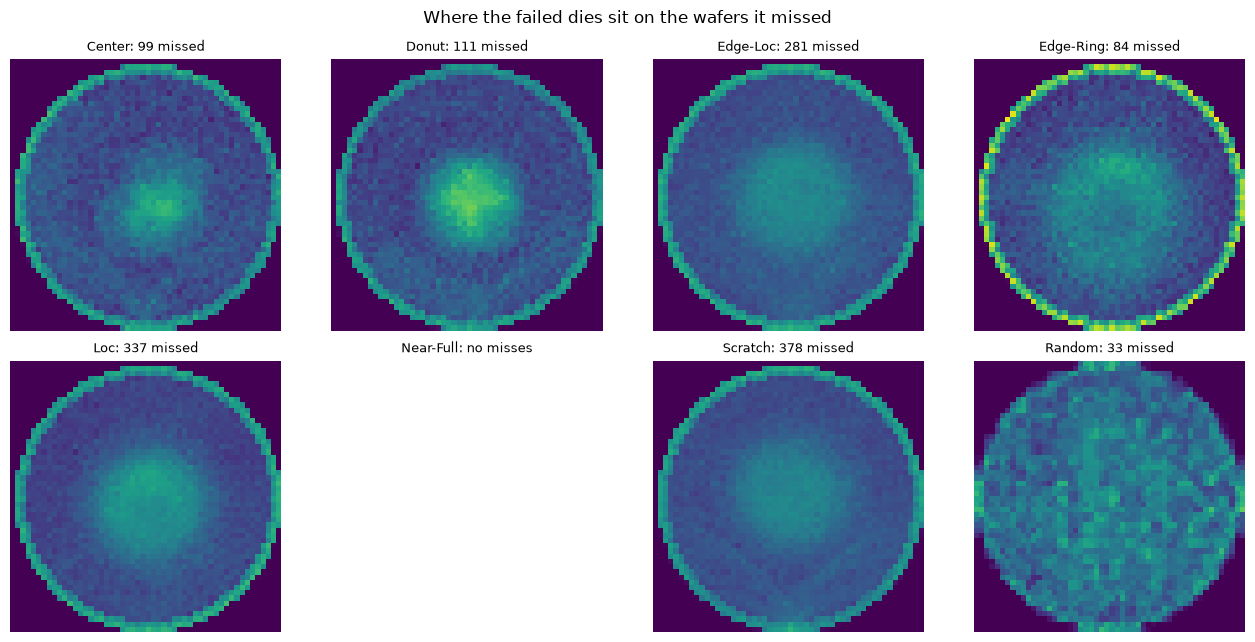

In [8]:
split = np.load("output/split.npz")
test_maps = split["maps"][split["test_idx"]]

plt.figure(figsize=(13, 6.5))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    missed = (y_test[:, i] == 1) & (y_pred[:, i] == 0)

    if missed.sum() == 0:
        plt.title(f"{wafer.DEFECTS[i]}: no misses", fontsize=9)
    else:
        plt.imshow((test_maps[missed] == 2).mean(axis=0), vmin=0, vmax=1)
        plt.title(f"{wafer.DEFECTS[i]}: {missed.sum()} missed", fontsize=9)
    plt.axis("off")

plt.suptitle("Where the failed dies sit on the wafers it missed")
plt.tight_layout()
plt.show()

**What you should see:** One average map per defect, of the wafers it missed. Where do the missed wafers have their
failure, and how does that differ from a typical wafer of that pattern in notebook 01 step 9?

## 9. Save every number

**Why this step:** Notebook 08 tests against the saved answers without opening the test part again.

**The problem:** Save the scores, the numbers per defect count, the mix-ups, and the answers themselves.

**How:** Four files. In `test_scores.csv` the `baseline_` columns are the simple model and `guess_f1` is the guess by share. The answers go in an `.npz` with `np.savez_compressed`, the tables in `.csv` files.

In [9]:
os.makedirs("output", exist_ok=True)

with open("output/test_scores.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["rank", "defect", "recall", "precision", "f1",
                     "baseline_recall", "baseline_precision", "baseline_f1", "guess_f1"])
    rank = 1
    for i in order:
        writer.writerow([rank, wafer.DEFECTS[i], round(recall[i], 4), round(precision[i], 4), round(f1[i], 4),
                         round(base_recall[i], 4), round(base_precision[i], 4), round(base_f1[i], 4),
                         round(luck_f1[i], 4)])
        rank += 1

with open("output/test_per_number_of_defects.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["defects_on_wafer", "wafers", "all_eight_right"])
    for n, count, score in per_number:
        writer.writerow([n, count, round(score, 4)])
    writer.writerow(["all", len(y_test), round(all_right, 4)])

with open("output/test_mixups.csv", "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["missed"] + wafer.DEFECTS)
    for i in range(8):
        writer.writerow([wafer.DEFECTS[i]] + list(mixups[i]))

np.savez_compressed("output/test_predictions.npz", y_test=y_test, y_pred=y_pred, y_base=y_base, y_luck=y_luck)
print("Saved test_scores.csv, test_per_number_of_defects.csv, test_mixups.csv and test_predictions.npz")

Saved test_scores.csv, test_per_number_of_defects.csv, test_mixups.csv and test_predictions.npz


**What you should see:** One "Saved" line with four file names.

## What this means

The test scores, the ranking and the mix-ups are saved in `output/`. Notebook 07 tests the same model on wafers I
made myself, notebook 08 checks every requirement against these files.

## Functions in this notebook

| Function | What it does | Where to read more |
|---|---|---|
| `joblib.load` | opens a saved model | [docs](https://joblib.readthedocs.io/en/stable/generated/joblib.load.html) |
| `.predict` | the model's answers, 0 or 1 per defect | [docs](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) |
| `np.argmin` | the position of the smallest number | [docs](https://numpy.org/doc/stable/reference/generated/numpy.argmin.html) |
| `.sum(axis=1)` | adds up every row, here the defects per wafer | [docs](https://numpy.org/doc/stable/reference/generated/numpy.sum.html) |
| `np.lexsort` | sorts by one key, and by a second one on ties | [docs](https://numpy.org/doc/stable/reference/generated/numpy.lexsort.html) |
| `np.zeros` | a table full of zeros | [docs](https://numpy.org/doc/stable/reference/generated/numpy.zeros.html) |
| `.mean(axis=0)` | the average per square over many wafers | [docs](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) |